# Task 2: Unemployment analysis (India)
This notebook looks at unemployment in India by state and over time, mainly to see what COVID-19 did to it. I used pandas, matplotlib and seaborn.

The data is from Kaggle ("Unemployment in India", monthly totals, Jan 2016 to Aug 2021). I put a cleaned copy in `../data/unemployment.csv`. The original `Unemployment_Rate_M_Total.txt` works too if you put it next to the notebook.

In [1]:
# imports and plot defaults
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})

# nationwide lockdown started 25 March 2020, so I use this as the before/after cutoff
LOCKDOWN = pd.Timestamp("2020-03-25")

## 1. Loading and cleaning

In [2]:
# find the csv (checking a few likely names)
candidates = [Path("Unemployment in India.csv"), Path("unemployment.csv"),
              Path("../data/unemployment.csv"), Path("../data/Unemployment in India.csv"),
              Path("Unemployment_Rate_M_Total.txt"), Path("../data/Unemployment_Rate_M_Total.txt")]
DATA_PATH = next((p for p in candidates if p.exists()), None)
assert DATA_PATH, "CSV not found - download it from Kaggle and set DATA_PATH manually."

# The raw Kaggle .txt export has a title line above the header - skip it if present
with open(DATA_PATH) as fh:
    skip = 0 if fh.readline().lower().startswith("region") else 1
df = pd.read_csv(DATA_PATH, skiprows=skip, skipinitialspace=True)

# Kaggle headers contain stray spaces - strip them, then give columns short names
df.columns = df.columns.str.strip()
df = df.rename(columns={
    "Region": "region", "Date": "date", "Frequency": "frequency",
    "Estimated Unemployment Rate (%)": "unemployment_rate",
    "Estimated Employed": "employed",
    "Estimated Labour Participation Rate (%)": "labour_participation",
    "Region.1": "zone", "Area": "area"})
df.head()

,region,date,frequency,unemployment_rate,employed,labour_participation
0,Andhra Pradesh,31-01-2016,M,17.91,20626291.0,62.67
1,Andhra Pradesh,29-02-2016,M,9.98,19334918.0,53.50
2,Andhra Pradesh,31-03-2016,M,10.72,19646970.0,54.73
3,Andhra Pradesh,30-04-2016,M,5.51,18929583.0,49.76
4,Andhra Pradesh,31-05-2016,M,6.29,21163390.0,56.02


In [3]:
print("Shape (rows, columns):", df.shape)
print("\nDuplicate rows:", df.duplicated().sum())
print("\nNull values per column:")
print(df.isnull().sum())
print("\nData types (before conversion):")
print(df.dtypes)

Shape (rows, columns): (1822, 6)

Duplicate rows: 0

Null values per column:
region                  0
date                    0
frequency               0
unemployment_rate       0
employed                0
labour_participation    0
dtype: int64

Data types (before conversion):
region                      str
date                        str
frequency                   str
unemployment_rate       float64
employed                float64
labour_participation    float64
dtype: object


In [4]:
# cleaning and fixing types
df = df.dropna(how="all").copy()                          # drop fully empty rows
for c in df.select_dtypes("object"):
    df[c] = df[c].str.strip()                             # remove stray whitespace in text

df["date"] = pd.to_datetime(df["date"], dayfirst=True)    # dates are dd-mm-yyyy
for c in ["unemployment_rate", "employed", "labour_participation"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

df = df.dropna(subset=["unemployment_rate"])              # rows without a target value are unusable

# The file includes an all-India aggregate; keep it apart so it is not averaged in with the states
national = df[df["region"] == "India"].copy()
df = df[df["region"] != "India"].copy()
df["month"] = df["date"].dt.to_period("M")
df["period"] = np.where(df["date"] < LOCKDOWN, "Pre-COVID", "Post-COVID")

print("Shape after cleaning:", df.shape)
print("Date range:", df["date"].min().date(), "->", df["date"].max().date())
print("Regions:", df["region"].nunique())
df.dtypes

Shape after cleaning: (1754, 8)
Date range: 2016-01-31 -> 2021-08-31
Regions: 27


region                             str
date                    datetime64[us]
frequency                          str
unemployment_rate              float64
employed                       float64
labour_participation           float64
month                        period[M]
period                             str
dtype: object

Had to clean a few things first. The file has a title line above the header, there were extra spaces in the column names and values, and the dates were strings so I converted them. No missing values, and I ended up with 27 states. Some states don't have all the months (Sikkim, Meghalaya and Tripura have fewer), so keep that in mind when comparing them. I put the "India" rows in their own table because they're a total, not a state.

## 2. Averages by region and by month

In [5]:
# average of each indicator per state
region_avg = (df.groupby("region")[["unemployment_rate", "employed", "labour_participation"]]
                .mean().round(2).sort_values("unemployment_rate", ascending=False))
region_avg

,unemployment_rate,employed,labour_participation
region,,,
Tripura,22.94,1428164.60,58.63
Haryana,18.64,7388811.21,42.30
Jammu & Kashmir,15.14,3470941.99,40.86
Delhi,11.67,5267227.41,39.59
Rajasthan,11.41,19767672.47,40.49
Himachal Pradesh,11.23,2200209.93,42.20
Jharkhand,10.54,9461969.34,41.08
Goa,10.25,518287.91,45.88
Bihar,10.15,26840555.16,39.44


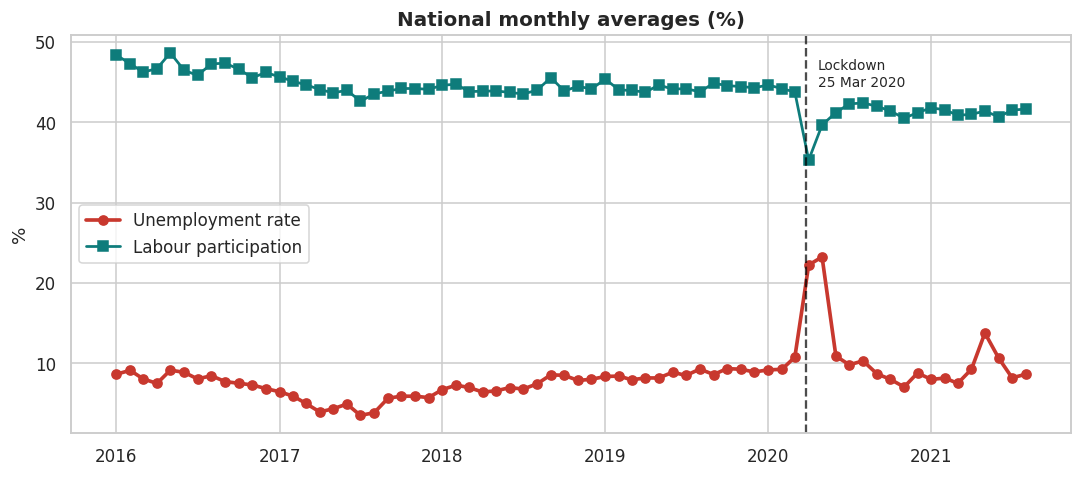

In [6]:
# monthly trend, averaged over all states
monthly = df.groupby("month")[["unemployment_rate", "labour_participation"]].mean()
monthly.index = monthly.index.to_timestamp()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(monthly.index, monthly["unemployment_rate"], marker="o", lw=2.4, color="#C8382E", label="Unemployment rate")
ax.plot(monthly.index, monthly["labour_participation"], marker="s", lw=1.8, color="#0E7C7B", label="Labour participation")
ax.axvline(LOCKDOWN, ls="--", color="black", alpha=.7)
ax.annotate("Lockdown\n25 Mar 2020", (LOCKDOWN, monthly["labour_participation"].max()), xytext=(8, -4),
            textcoords="offset points", va="top", fontsize=9)
ax.set(title="National monthly averages (%)", xlabel="", ylabel="%")
ax.legend(loc="center left")
plt.tight_layout(); plt.show()

In [7]:
# peak and low months
peak = monthly["unemployment_rate"].idxmax()
low = monthly["unemployment_rate"].idxmin()
print(f"Highest national average unemployment: {monthly['unemployment_rate'].max():.1f}% in {peak:%B %Y}")
print(f"Lowest national average unemployment:  {monthly['unemployment_rate'].min():.1f}% in {low:%B %Y}")
ip = national.loc[national["unemployment_rate"].idxmax()]
print(f"Official all-India figure peaked at {ip['unemployment_rate']:.1f}% in {ip['date']:%B %Y}")

Highest national average unemployment: 23.2% in May 2020
Lowest national average unemployment:  3.5% in July 2017
Official all-India figure peaked at 23.5% in April 2020


Unemployment stays at about 7% on average until early 2020. Then it shoots up to over 22% in April and May 2020 (the peak is 23.2% in May) and is back to around 11% by June. There's a smaller jump in May 2021, probably the second wave. The lowest month was July 2017 (3.5%).

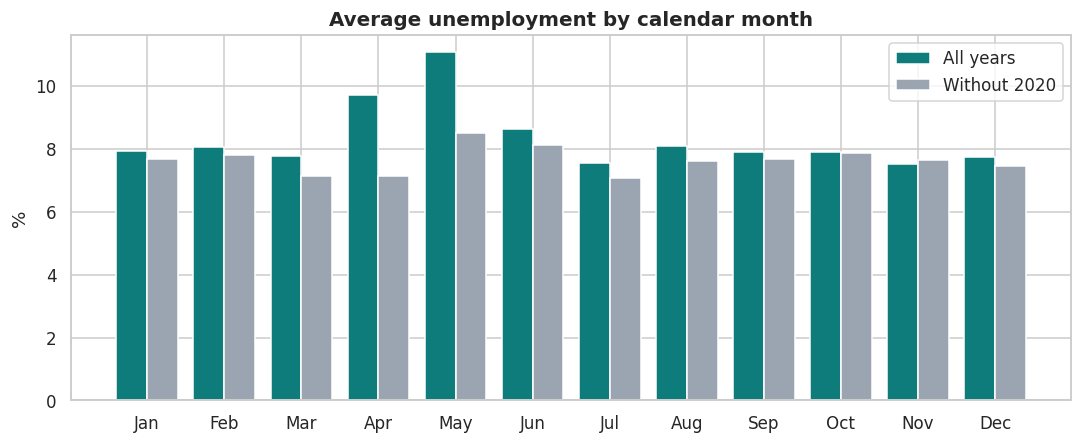

month_name,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
all years,7.9,8.1,7.8,9.7,11.1,8.6,7.6,8.1,7.9,7.9,7.5,7.7
without 2020,7.7,7.8,7.1,7.1,8.5,8.1,7.1,7.6,7.7,7.9,7.6,7.5


In [8]:
# average for each calendar month (all Januaries together, all Februaries, etc.)
order = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
df["month_name"] = df["date"].dt.strftime("%b")

all_years = df.groupby("month_name")["unemployment_rate"].mean().reindex(order)
no_2020 = df[df["date"].dt.year != 2020].groupby("month_name")["unemployment_rate"].mean().reindex(order)

fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(12)
ax.bar(x - 0.2, all_years.values, width=0.4, color="#0E7C7B", label="All years")
ax.bar(x + 0.2, no_2020.values, width=0.4, color="#9AA5B1", label="Without 2020")
ax.set_xticks(x); ax.set_xticklabels(order)
ax.set(title="Average unemployment by calendar month", ylabel="%")
ax.legend()
plt.tight_layout(); plt.show()
pd.DataFrame({"all years": all_years, "without 2020": no_2020}).round(1).T

Grouping by calendar month, April (9.7%) and May (11.1%) stand out. Most of that comes from 2020: when I leave 2020 out they drop to 7.1% and 8.5%, and the whole year looks fairly flat at around 7 to 8%. So I don't see a real seasonal pattern here, the April and May bump is the lockdown.

## 3. Unemployment over time for a few states

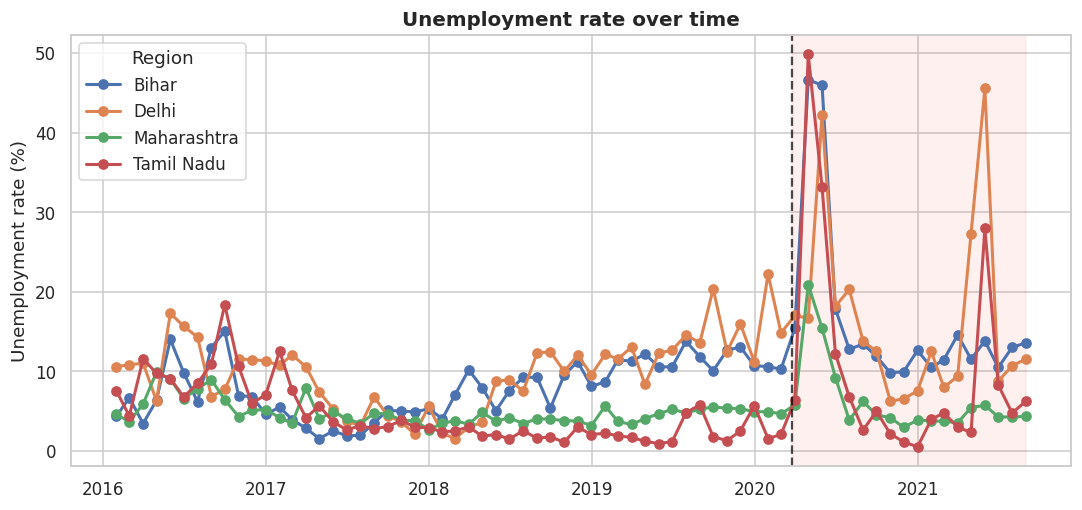

In [9]:
# states to compare - change as you like (falls back to the top 3 if none match)
wanted = ["Maharashtra", "Delhi", "Tamil Nadu", "Bihar"]
regions = [r for r in wanted if r in df["region"].unique()] or list(region_avg.index[:3])

ts = (df[df["region"].isin(regions)]
        .pivot_table(index="date", columns="region", values="unemployment_rate"))

fig, ax = plt.subplots(figsize=(10, 4.8))
for r in ts.columns:
    ax.plot(ts.index, ts[r], marker="o", lw=2, label=r)
ax.axvline(LOCKDOWN, ls="--", color="black", alpha=.7)
ax.axvspan(LOCKDOWN, ts.index.max(), color="red", alpha=.06)
ax.set(title="Unemployment rate over time", xlabel="", ylabel="Unemployment rate (%)")
ax.legend(title="Region")
plt.tight_layout(); plt.show()

Every state spikes in April/May 2020 but not by the same amount. Tamil Nadu and Bihar go up to about 50% and 47%, Delhi to 42%, and Maharashtra only to about 21%. By June they're all below 20% again. So the spike was huge but it didn't last long.

## 4. Top 10 states by average unemployment

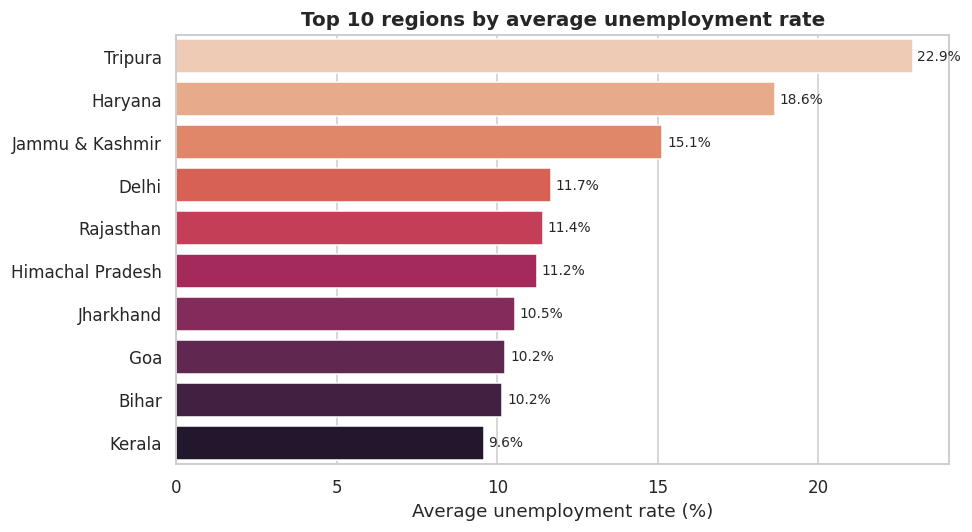

In [10]:
top10 = region_avg["unemployment_rate"].head(10).reset_index()

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=top10, y="region", x="unemployment_rate", palette="rocket_r", ax=ax)
for i, v in enumerate(top10["unemployment_rate"]):
    ax.text(v + .15, i, f"{v:.1f}%", va="center", fontsize=9)
ax.set(title="Top 10 regions by average unemployment rate", xlabel="Average unemployment rate (%)", ylabel="")
plt.tight_layout(); plt.show()

Tripura, Haryana and Jammu & Kashmir have the highest averages (about 23%, 19% and 15%). Gujarat, Meghalaya and Karnataka are the lowest at around 4%. This includes the COVID months, and Tripura has fewer months of data, so its number is less reliable.

## 5. Correlation heatmap

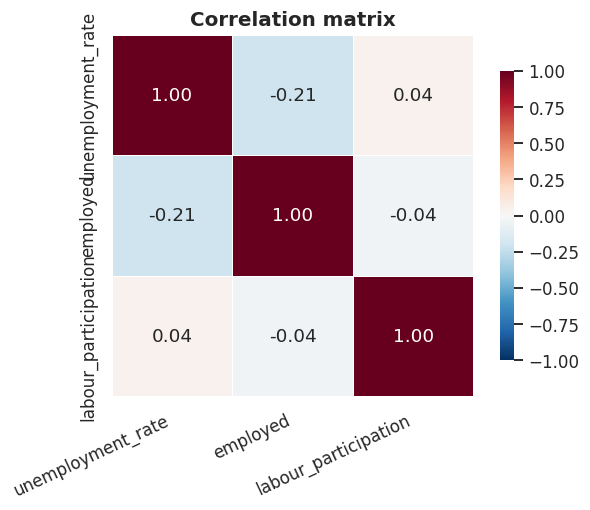

In [11]:
corr = df[["unemployment_rate", "employed", "labour_participation"]].corr()

fig, ax = plt.subplots(figsize=(6, 4.8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True,
            linewidths=.5, cbar_kws={"shrink": .8}, ax=ax)
ax.set_title("Correlation matrix")
plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.show()

There isn't much correlation between any of them. Unemployment and employed is -0.21, and unemployment and participation is about 0. I expected participation to drop when unemployment goes up, but this data doesn't really show that. The employed number depends a lot on how big the state is, so it's not great to compare across states anyway.

## 6. Before vs after the lockdown

In [12]:
# split at the lockdown date and compare means
cmp = (df.groupby("period")[["unemployment_rate", "employed", "labour_participation"]]
         .mean().round(2).loc[["Pre-COVID", "Post-COVID"]])
display(cmp)
print(f"National mean unemployment: {cmp.loc['Pre-COVID','unemployment_rate']:.1f}% -> "
      f"{cmp.loc['Post-COVID','unemployment_rate']:.1f}%")

,unemployment_rate,employed,labour_participation
period,,,
Pre-COVID,7.43,15766523.27,44.82
Post-COVID,10.77,14046927.99,41.12


National mean unemployment: 7.4% -> 10.8%


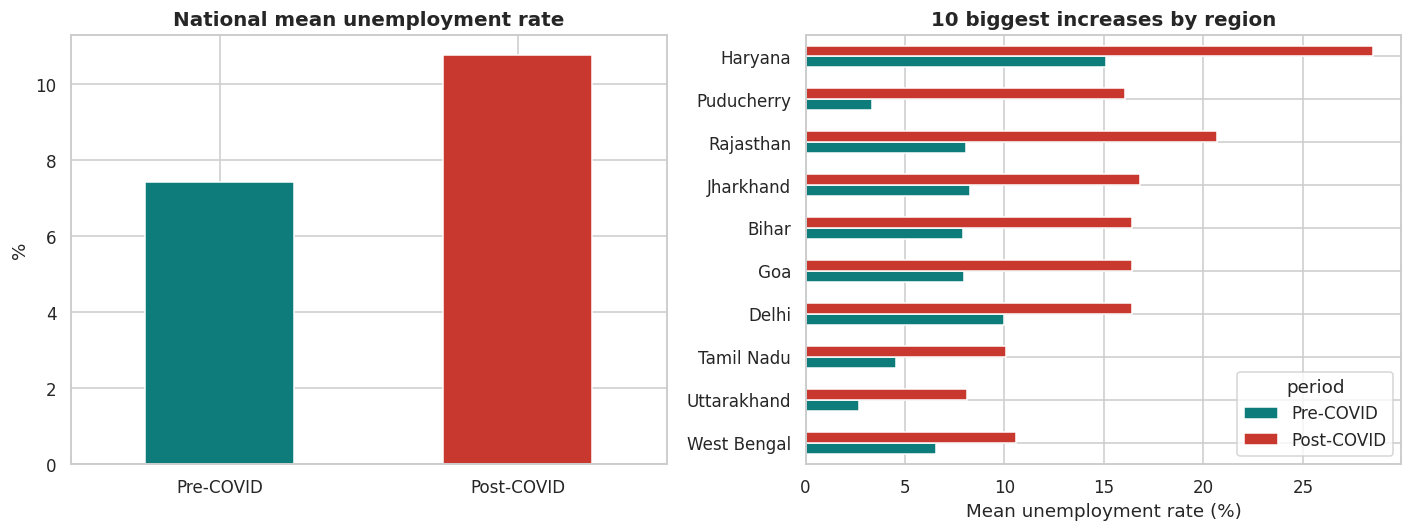

period,Post-COVID,Pre-COVID,change
region,,,
Haryana,28.52,15.08,13.45
Puducherry,16.04,3.35,12.68
Rajasthan,20.67,8.07,12.60
Jharkhand,16.82,8.28,8.53
Bihar,16.42,7.89,8.53
Goa,16.42,7.99,8.43
Delhi,16.39,9.97,6.43
Tamil Nadu,10.07,4.53,5.54
Uttarakhand,8.10,2.69,5.41


In [13]:
# change per state, then plot the 10 biggest increases
by_region = df.pivot_table(index="region", columns="period", values="unemployment_rate", aggfunc="mean")
by_region["change"] = by_region["Post-COVID"] - by_region["Pre-COVID"]
biggest = by_region.sort_values("change", ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cmp["unemployment_rate"].plot(kind="bar", color=["#0E7C7B", "#C8382E"], rot=0, ax=axes[0])
axes[0].set(title="National mean unemployment rate", xlabel="", ylabel="%")
biggest[["Pre-COVID", "Post-COVID"]][::-1].plot(kind="barh", color=["#0E7C7B", "#C8382E"], ax=axes[1])
axes[1].set(title="10 biggest increases by region", xlabel="Mean unemployment rate (%)", ylabel="")
plt.tight_layout(); plt.show()
biggest.round(2)

Average unemployment went from 7.4% before the lockdown to 10.8% after, and participation dropped from 44.8% to 41.1%. Haryana, Puducherry and Rajasthan had the biggest increases (12 to 13 points). Tripura and Assam went down, but Tripura was already really high before (25.5%). The "after" period goes all the way to Aug 2021 so it includes the recovery too, which is why the average only looks a bit higher even though the monthly chart shows a huge spike.

## 7. Conclusions
- Before 2020 unemployment was around 7% on average. After the lockdown it jumped to 22-23% in April and May 2020, then dropped back to about 11% by June. It went up a bit again in May 2021.
- States were hit very differently. Tamil Nadu, Bihar and Delhi went over 40% for a month, Maharashtra only reached about 21%. The states with the highest averages overall (Tripura, Haryana, J&K) aren't the same as the ones with the biggest increase after COVID (Haryana, Puducherry, Rajasthan).
- Unemployment, employment and participation aren't strongly related in this data.
- Things to keep in mind: the state averages aren't weighted by population, some states are missing months, and the "after" period mixes the shock with the recovery.